# 📊 Notebook 02-B: Data Cleaning & Preprocessing Pipeline
### PestAlertNet v2 — Desert Locust Early-Warning System

This notebook walks through the **complete data-cleaning and preprocessing pipeline**
that transforms raw field-survey records (FAO RAMSES) and NASA POWER agro-climatic
weather data into clean, model-ready tensors stored in data/processed/sequences.npz.

| Stage | Description |
|-------|-------------|
| **C1** | Raw data inventory & schema audit |
| **C2** | RAMSES field-survey cleaning (reliability / confirmation filters) |
| **C3** | Coordinate snapping to 0.5° × 0.625° grid |
| **C4** | NASA POWER sentinel detection & NaN imputation |
| **C5** | Feature engineering (rolling statistics, event counters) |
| **C6** | Train-only z-score scaling (no data leakage) |
| **C7** | Temporal embargo splits (28-day gap) |
| **C8** | Artifact validation & provenance checks |

> **Kernel**: pestalertnet (Python 3.12). Run *Kernel → Restart & Run All* for a fresh execution.

## 0 · Environment Setup

In [1]:
import sys, os, json, csv, datetime as dt, warnings
import pathlib, textwrap, collections
warnings.filterwarnings('ignore')

# ── Project root detection ──────────────────────────────────────────────────
_nb_path = pathlib.Path(globals().get('__vsc_ipynb_file__','') or
                        os.path.abspath('.')).resolve()
PROJECT_ROOT = (_nb_path.parent.parent if _nb_path.suffix == '.ipynb'
                else _nb_path)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

mpl.rcParams.update({
    'figure.facecolor':'#0d1117','axes.facecolor':'#161b22',
    'axes.edgecolor':'#30363d','axes.labelcolor':'#c9d1d9',
    'xtick.color':'#8b949e','ytick.color':'#8b949e',
    'grid.color':'#21262d','grid.linewidth':0.6,
    'text.color':'#c9d1d9','legend.facecolor':'#161b22',
    'legend.edgecolor':'#30363d','font.family':'DejaVu Sans',
    'figure.dpi':110,
})
EMERALD='#3fb950'; AMBER='#d29922'; RED='#f85149'; CYAN='#79c0ff'; PURPLE='#bc8cff'

OUTPUTS = PROJECT_ROOT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)

RAW  = PROJECT_ROOT / 'data' / 'raw'
PROC = PROJECT_ROOT / 'data' / 'processed'

print(f"Project root : {PROJECT_ROOT}")
print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}  |  Pandas: {pd.__version__}")

Project root : D:\Project\pestalertnet_v2
Python       : 3.12.4
NumPy        : 2.0.1  |  Pandas: 2.2.2


## C1 · Raw Data Inventory & Schema Audit

Before any cleaning, we catalogue what raw files exist and inspect their shapes, 
column names, and dtypes.

In [2]:
# ── C1-A: RAMSES raw observations ───────────────────────────────────────────
ramses_path = RAW / 'ramses_observations_global.csv'
ramses_df   = pd.read_csv(ramses_path, low_memory=False)

print(f"{'='*60}")
print(f"FAO RAMSES Global Observations")
print(f"{'='*60}")
print(f"  Rows      : {len(ramses_df):,}")
print(f"  Columns   : {ramses_df.shape[1]}")
print(f"\nColumn names:")
for c in ramses_df.columns:
    dtype = str(ramses_df[c].dtype)
    null_pct = 100*ramses_df[c].isna().mean()
    print(f"  {c:<40} {dtype:<12} {null_pct:.1f}% null")

FAO RAMSES Global Observations
  Rows      : 176,081
  Columns   : 72

Column names:
  OBJECTID                                 int64        0.0% null
  Breeding                                 object       98.3% null
  Colour                                   object       76.9% null
  Application_Method                       object       87.6% null
  Application_Type                         object       87.6% null
  Control_Method                           object       87.6% null
  Pesticide_Formulation                    object       87.6% null
  Pesticide_Name                           object       87.6% null
  Pesticide_Quantity_Unit                  object       87.6% null
  Day                                      int64        0.0% null
  Month                                    object       0.0% null
  Quarter                                  object       0.0% null
  Year                                     int64        0.0% null
  Density_Description                      object

  Soil_Type                                object       78.7% null
  Topography                               object       76.6% null
  Vegetation_Density                       object       0.2% null
  Vegetation_State                         object       0.2% null
  Activity                                 object       93.7% null
  Behaviour                                object       78.9% null
  Locust_Phase                             object       76.7% null
  Locust_Presence                          object       0.0% null
  Locust_Type                              object       0.0% null
  RAMSES_Locust_Type                       object       0.0% null
  Maturity                                 object       76.8% null
  Asset                                    object       0.0% null
  Data_Collection_Method                   object       0.0% null
  Obs_Date                                 int64        0.0% null
  Observation_Confirmation                 object       0.0% null
  Ob

  Last_Rain_Amount_Description             object       72.9% null
  Last_Rain_End_Date                       int64        0.0% null
  Wind_Direction_From                      object       66.7% null
  Latitude                                 float64      0.0% null
  Longitude                                float64      0.0% null
  Control_Mortality_Sum                    int64        0.0% null
  Crop_Damage_Sum                          float64      100.0% null
  Pasture_Damage_Sum                       int64        0.0% null
  Pesticide_Quantity_Sum                   int64        0.0% null
  Protected_Area_Sum                       int64        0.0% null
  Sum__Area_Treated_ha                     int64        0.0% null
  Maximum_Density_Sum                      int64        0.0% null
  Minimum_Density_Sum                      int64        0.0% null
  Avg__Soil_Moisture_Depth_Range_          int64        0.0% null
  Avg__Soil_Moisture_Depth_Range1          int64        0.0% null
  Band

In [3]:
# ── C1-B: NASA POWER global weather grid ────────────────────────────────────
power_path = RAW / 'power_cells_global.csv'
# read first 5 rows to inspect schema (file is ~124 MB)
power_head = pd.read_csv(power_path, nrows=5)
power_wc   = sum(1 for _ in open(power_path, encoding='utf-8')) - 1  # exclude header

print(f"{'='*60}")
print(f"NASA POWER Global Weather Grid")
print(f"{'='*60}")
print(f"  Rows (data): {power_wc:,}")
print(f"  Columns    : {list(power_head.columns)}")
print(f"\nSample rows:")
print(power_head.to_string(index=False))

NASA POWER Global Weather Grid
  Rows (data): 2,806,842
  Columns    : ['lat', 'lon', 'date', 'T2M', 'RH2M', 'PRECTOTCORR', 'WS2M']

Sample rows:
 lat    lon       date   T2M  RH2M  PRECTOTCORR  WS2M
 0.0 20.625 2023-01-01 24.69 89.64         0.26  0.16
 0.0 20.625 2023-01-02 25.35 85.33         0.31  0.16
 0.0 20.625 2023-01-03 25.28 88.70         0.70  0.19
 0.0 20.625 2023-01-04 25.01 89.26         0.82  0.24
 0.0 20.625 2023-01-05 23.76 90.81         0.57  0.16


In [4]:
# ── C1-C: Processed artifacts ───────────────────────────────────────────────
npz = np.load(PROC / 'sequences.npz')
with open(PROC / 'feature_manifest.yaml') as f:
    import yaml; manifest = yaml.safe_load(f)
with open(PROC / 'scaler_stats.json') as f:
    scaler = json.load(f)

print(f"{'='*60}")
print(f"Processed Artifacts")
print(f"{'='*60}")
for k in npz.files:
    arr = npz[k]
    print(f"  sequences.npz['{k}'] : shape={arr.shape}  dtype={arr.dtype}")
print(f"\n  Feature manifest   : {manifest['n_features']} features, "
      f"{manifest['input_days']}-day window, "
      f"{manifest['horizon']}-day horizon, "
      f"{manifest['embargo_days']}-day embargo")
print(f"\n  Scaler stats       : {len(scaler['mean'])} continuous channels, "
      f"train_only={scaler['train_only']}, "
      f"n_train_rows={scaler['n_train_rows']:,}")

Processed Artifacts


  sequences.npz['X'] : shape=(48544, 21, 25)  dtype=float32
  sequences.npz['y'] : shape=(48544,)  dtype=int8
  sequences.npz['cell'] : shape=(48544,)  dtype=<U12
  sequences.npz['date'] : shape=(48544,)  dtype=<U10
  sequences.npz['split'] : shape=(48544,)  dtype=int8

  Feature manifest   : 25 features, 21-day window, 7-day horizon, 28-day embargo

  Scaler stats       : 18 continuous channels, train_only=True, n_train_rows=35,583


## C2 · RAMSES Field-Survey Cleaning

FAO RAMSES records carry two reliability metadata fields that must be filtered:

| Filter | Rule |
|--------|------|
| Observation_Reliability == "DUBIOUS" | Observer flagged low confidence — **excluded** |
| Observation_Confirmation == "UNCLEAR" | Ground-truth ambiguous — **excluded** |

We also classify observations by **locust phase** to isolate *gregarious-form* events 
(the outbreak precursor) from solitary background populations.

In [5]:
# ── C2-A: Reliability filter ─────────────────────────────────────────────────
print(f"Total raw RAMSES records: {len(ramses_df):,}\n")

# Reliability distribution
rel_counts = ramses_df['Observation_Reliability'].value_counts(dropna=False)
print("Observation_Reliability distribution:")
for v, c in rel_counts.items():
    flag = " ← EXCLUDED" if v == "DUBIOUS" else ""
    print(f"  {str(v):<20} {c:>7,}  ({100*c/len(ramses_df):.1f}%){flag}")

conf_counts = ramses_df['Observation_Confirmation'].value_counts(dropna=False)
print("\nObservation_Confirmation distribution:")
for v, c in conf_counts.items():
    flag = " ← EXCLUDED" if v == "UNCLEAR" else ""
    print(f"  {str(v):<20} {c:>7,}  ({100*c/len(ramses_df):.1f}%){flag}")

# Apply filter
mask_dubious = ramses_df['Observation_Reliability'] == 'DUBIOUS'
mask_unclear = ramses_df['Observation_Confirmation'] == 'UNCLEAR'
mask_excl    = mask_dubious | mask_unclear
clean_df     = ramses_df[~mask_excl].copy()

print(f"\nAfter filtering → Kept: {len(clean_df):,}  Excluded: {mask_excl.sum():,} "
      f"({100*mask_excl.mean():.2f}% removed)")

Total raw RAMSES records: 176,081

Observation_Reliability distribution:
  RELIABLE             176,073  (100.0%)
  DUBIOUS                    8  (0.0%) ← EXCLUDED

Observation_Confirmation distribution:
  CONFIRMED            176,071  (100.0%)
  UNCLEAR                   10  (0.0%) ← EXCLUDED



After filtering → Kept: 176,071  Excluded: 10 (0.01% removed)


In [6]:
# ── C2-B: Locust phase & presence classification ─────────────────────────────
GREG_TYPES  = {'BAND', 'SWARM', 'HOPPER GROUPS', 'ADULT GROUPS'}
GREG_PHASE  = {'GREGARIOUS', 'T_CONGREGANS'}

presence_counts = clean_df['Locust_Presence'].value_counts(dropna=False)
print("Locust_Presence distribution (cleaned):")
for v, c in presence_counts.items():
    print(f"  {str(v):<20} {c:>7,}  ({100*c/len(clean_df):.1f}%)")

present_df = clean_df[clean_df['Locust_Presence'] == 'PRESENT'].copy()

# Classify gregarious
def is_gregarious(row):
    return (row.get('Locust_Type','') in GREG_TYPES or
            row.get('RAMSES_Locust_Type','') in GREG_TYPES or
            row.get('Locust_Phase','') in GREG_PHASE or
            'GROUPS' in str(row.get('Behaviour','')))

present_df['is_gregarious'] = present_df.apply(is_gregarious, axis=1)
greg_count = present_df['is_gregarious'].sum()
print(f"\nPresent records        : {len(present_df):,}")
print(f"  → Gregarious form   : {greg_count:,}  ({100*greg_count/len(present_df):.1f}%)  ← label=1")
print(f"  → Solitary/other    : {len(present_df)-greg_count:,}  ({100*(1-greg_count/len(present_df)):.1f}%)  ← label=0")

Locust_Presence distribution (cleaned):
  ABSENT               134,948  (76.6%)
  PRESENT               41,123  (23.4%)



Present records        : 41,123
  → Gregarious form   : 21,541  (52.4%)  ← label=1
  → Solitary/other    : 19,582  (47.6%)  ← label=0


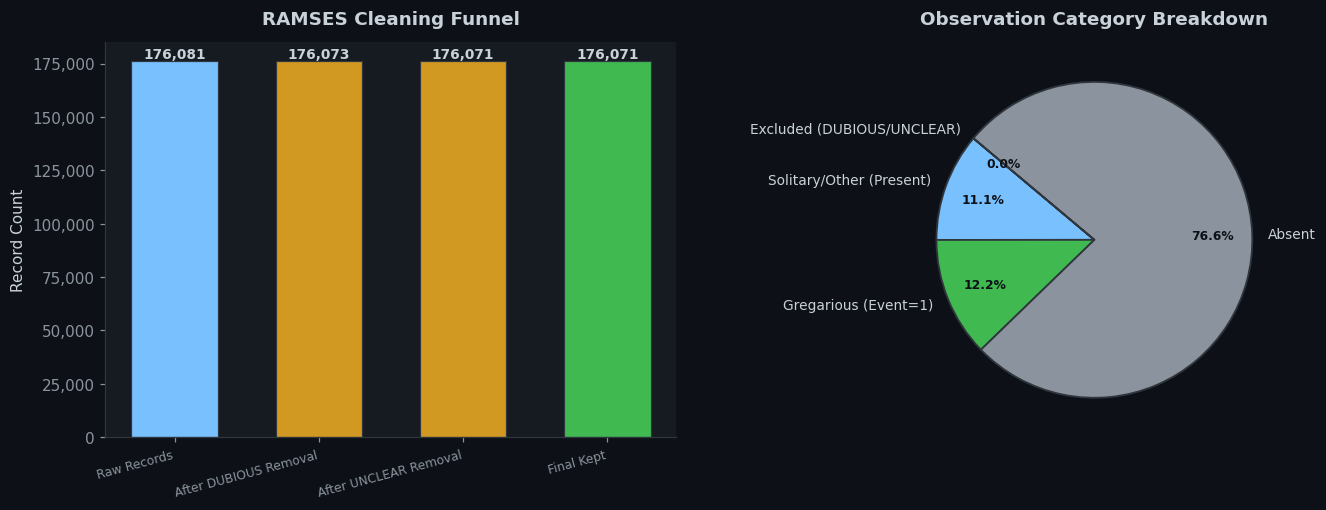

Fig 1 saved -> outputs/nb02b_fig1_ramses_cleaning_funnel.png


In [7]:
# C2-C: Figure -- cleaning funnel chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('#0d1117')

# Left: Exclusion waterfall
stages = ['Raw Records', 'After DUBIOUS Removal', 'After UNCLEAR Removal', 'Final Kept']
n_total  = len(ramses_df)
n_post_d = len(ramses_df[~mask_dubious])
n_post_u = len(clean_df)
values   = [n_total, n_post_d, n_post_u, n_post_u]
colors   = [CYAN, AMBER, AMBER, EMERALD]
ax = axes[0]
ax.set_facecolor('#161b22')
bars = ax.bar(stages, values, color=colors, edgecolor='#30363d', linewidth=0.8, width=0.6)
ax.set_title('RAMSES Cleaning Funnel', color='#c9d1d9', fontweight='bold', pad=12)
ax.set_ylabel('Record Count', color='#c9d1d9')
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda x,_: f'{int(x):,}'))
for bar, val in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+200, f'{val:,}',
            ha='center', va='bottom', color='#c9d1d9', fontsize=9, fontweight='bold')
ax.tick_params(colors='#8b949e')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.set_xticklabels(stages, rotation=15, ha='right', fontsize=8)

# Right: Phase distribution pie
phase_data   = [len(present_df)-greg_count, greg_count,
                len(clean_df)-len(present_df), mask_excl.sum()]
phase_labels = ['Solitary/Other (Present)', 'Gregarious (Event=1)',
                'Absent', 'Excluded (DUBIOUS/UNCLEAR)']
phase_colors = [CYAN, EMERALD, '#8b949e', RED]
ax2 = axes[1]
ax2.set_facecolor('#0d1117')
wedges, texts, autotexts = ax2.pie(phase_data, labels=phase_labels, colors=phase_colors,
    autopct='%1.1f%%', startangle=140, pctdistance=0.75,
    wedgeprops=dict(edgecolor='#30363d', linewidth=1.2))
for t in texts: t.set_color('#c9d1d9'); t.set_fontsize(9)
for a in autotexts: a.set_color('#0d1117'); a.set_fontweight('bold'); a.set_fontsize(8)
ax2.set_title('Observation Category Breakdown', color='#c9d1d9', fontweight='bold', pad=12)

plt.tight_layout(pad=2)
fig.savefig(OUTPUTS/'nb02b_fig1_ramses_cleaning_funnel.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Fig 1 saved -> outputs/nb02b_fig1_ramses_cleaning_funnel.png")


## C3 · Coordinate Snapping to Regular Grid

GPS coordinates from field surveys are irregularly spaced. We snap each lat/lon
to the nearest **0.5° × 0.625°** grid cell — matching NASA POWER's resolution — 
so observations and weather data share the same spatial key.

`
snap(lat) = round(lat / 0.5) × 0.5     → 0.5° step
snap(lon) = round(lon / 0.625) × 0.625  → 0.625° step
`

In [8]:
# ── C3-A: Demonstrate snapping on a sample ───────────────────────────────────
def snap_lat(lat): return round(round(float(lat) / 0.5) * 0.5, 4)
def snap_lon(lon): return round(round(float(lon) / 0.625) * 0.625, 4)

# Sample 8 raw coordinates
sample = clean_df[['Latitude','Longitude']].dropna().sample(8, random_state=42)
print(f"{'Raw Lat':>10}  {'Raw Lon':>10}  {'Snapped Lat':>12}  {'Snapped Lon':>12}  {'Δlat':>8}  {'Δlon':>8}")
print("-"*68)
for _, row in sample.iterrows():
    lat, lon = float(row['Latitude']), float(row['Longitude'])
    slat, slon = snap_lat(lat), snap_lon(lon)
    print(f"{lat:>10.4f}  {lon:>10.4f}  {slat:>12.4f}  {slon:>12.4f}  "
          f"{abs(lat-slat):>8.4f}  {abs(lon-slon):>8.4f}")

# Overall snapping error stats
lats = clean_df['Latitude'].dropna().astype(float)
lons = clean_df['Longitude'].dropna().astype(float)
dlat = (lats - lats.apply(snap_lat)).abs()
dlon = (lons - lons.apply(snap_lon)).abs()
print(f"\nSnapping error — Latitude  : mean={dlat.mean():.4f}°  max={dlat.max():.4f}°")
print(f"Snapping error — Longitude : mean={dlon.mean():.4f}°  max={dlon.max():.4f}°")

clean_df['cell_lat'] = lats.apply(snap_lat)
clean_df['cell_lon'] = lons.apply(snap_lon)
unique_cells = clean_df.groupby(['cell_lat','cell_lon']).size().reset_index(name='obs_count')
print(f"\nUnique grid cells with observations: {len(unique_cells):,}")
print(f"Observations per cell — median={unique_cells['obs_count'].median():.0f}  "
      f"max={unique_cells['obs_count'].max():,}")

   Raw Lat     Raw Lon   Snapped Lat   Snapped Lon      Δlat      Δlon
--------------------------------------------------------------------
   27.3304     53.1778       27.5000       53.1250    0.1696    0.0528
   17.5374     38.5245       17.5000       38.7500    0.0374    0.2255
   33.5804      9.6680       33.5000        9.3750    0.0804    0.2930
   22.0015     36.3701       22.0000       36.2500    0.0015    0.1201
   26.0231     43.2225       26.0000       43.1250    0.0231    0.0975
   28.3236     -0.0811       28.5000        0.0000    0.1764    0.0811
   19.8608     37.2016       20.0000       37.5000    0.1392    0.2984
   27.3256      0.1108       27.5000        0.0000    0.1744    0.1108



Snapping error — Latitude  : mean=0.1262°  max=0.2500°
Snapping error — Longitude : mean=0.1569°  max=0.3125°



Unique grid cells with observations: 2,070
Observations per cell — median=15  max=3,932


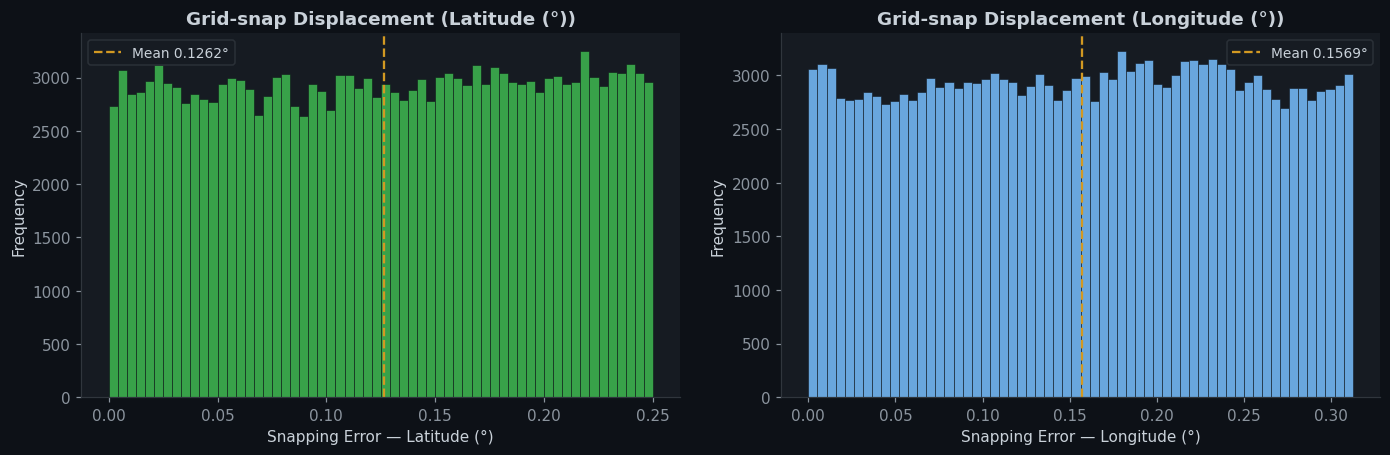

Fig 2 saved → outputs/nb02b_fig2_coordinate_snap_error.png


In [9]:
# ── C3-B: Figure — Snapping displacement distribution ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.patch.set_facecolor('#0d1117')

for ax, data, label, color in zip(axes,
        [dlat, dlon], ['Latitude (°)', 'Longitude (°)'], [EMERALD, CYAN]):
    ax.set_facecolor('#161b22')
    ax.hist(data, bins=60, color=color, edgecolor='#0d1117', linewidth=0.4, alpha=0.85)
    ax.axvline(data.mean(), color=AMBER, lw=1.5, ls='--', label=f'Mean {data.mean():.4f}°')
    ax.set_xlabel(f'Snapping Error — {label}', color='#c9d1d9')
    ax.set_ylabel('Frequency', color='#c9d1d9')
    ax.set_title(f'Grid-snap Displacement ({label})', color='#c9d1d9', fontweight='bold')
    ax.legend(fontsize=9)
    ax.tick_params(colors='#8b949e')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout(pad=2)
fig.savefig(OUTPUTS/'nb02b_fig2_coordinate_snap_error.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Fig 2 saved → outputs/nb02b_fig2_coordinate_snap_error.png")

## C4 · NASA POWER Sentinel Detection & NaN Imputation

NASA POWER fills missing values with a sentinel of **−999**. We replace these with 
NaN and also create **binary mask channels** (1 = data was missing) so the model 
can learn from missingness patterns. The 4 raw weather variables are:

| Index | Variable | Description |
|-------|----------|-------------|
| 0 | T2M | 2-m air temperature (°C) |
| 1 | RH2M | 2-m relative humidity (%) |
| 2 | PRECTOTCORR | Precipitation (mm/day) |
| 3 | WS2M | 2-m wind speed (m/s) |

In [10]:
# ── C4-A: Load processed tensor and inspect sentinel handling ─────────────────
X     = npz['X']        # (N, 21, 25)
y     = npz['y']
split = npz['split']
dates = npz['date']
cells = npz['cell']

FEATURES = manifest['features']
BIN_IDX  = manifest.get('binary_idx',  list(range(4,11)))  # 7 binary cols (indices 4-10)
CONT_IDX = scaler['cont_idx']

print(f"Loaded tensor X: {X.shape}  (N sequences × 21 days × 25 features)")
print(f"Labels y: {y.shape}  positives={y.sum():,} ({100*y.mean():.2f}%)")
print(f"\nBinary channels  (indices {BIN_IDX[:3]}…) — raw 0/1 missingness mask")
print(f"Continuous channels (indices {CONT_IDX[:5]}…) — z-score standardised")

# Check the mask channels: columns 4-7 are w_mask_T2M/RH2M/PRECTOT/WS2M
# They should sum to show true missingness rates
print("\nMissingness rates from mask channels (mean over all N×21 steps):")
var_names = ['T2M','RH2M','PRECTOTCORR','WS2M']
for i, vname in enumerate(var_names):
    mask_col = i + 4   # w_mask_* channels start at index 4
    miss_rate = X[:, :, mask_col].mean() * 100
    print(f"  {vname:<15} → {miss_rate:.3f}% missing")

Loaded tensor X: (48544, 21, 25)  (N sequences × 21 days × 25 features)
Labels y: (48544,)  positives=8,358 (17.22%)

Binary channels  (indices [4, 5, 6]…) — raw 0/1 missingness mask
Continuous channels (indices [0, 1, 2, 3, 11]…) — z-score standardised

Missingness rates from mask channels (mean over all N×21 steps):
  T2M             → 0.000% missing
  RH2M            → 0.000% missing
  PRECTOTCORR     → 0.000% missing
  WS2M            → 0.000% missing


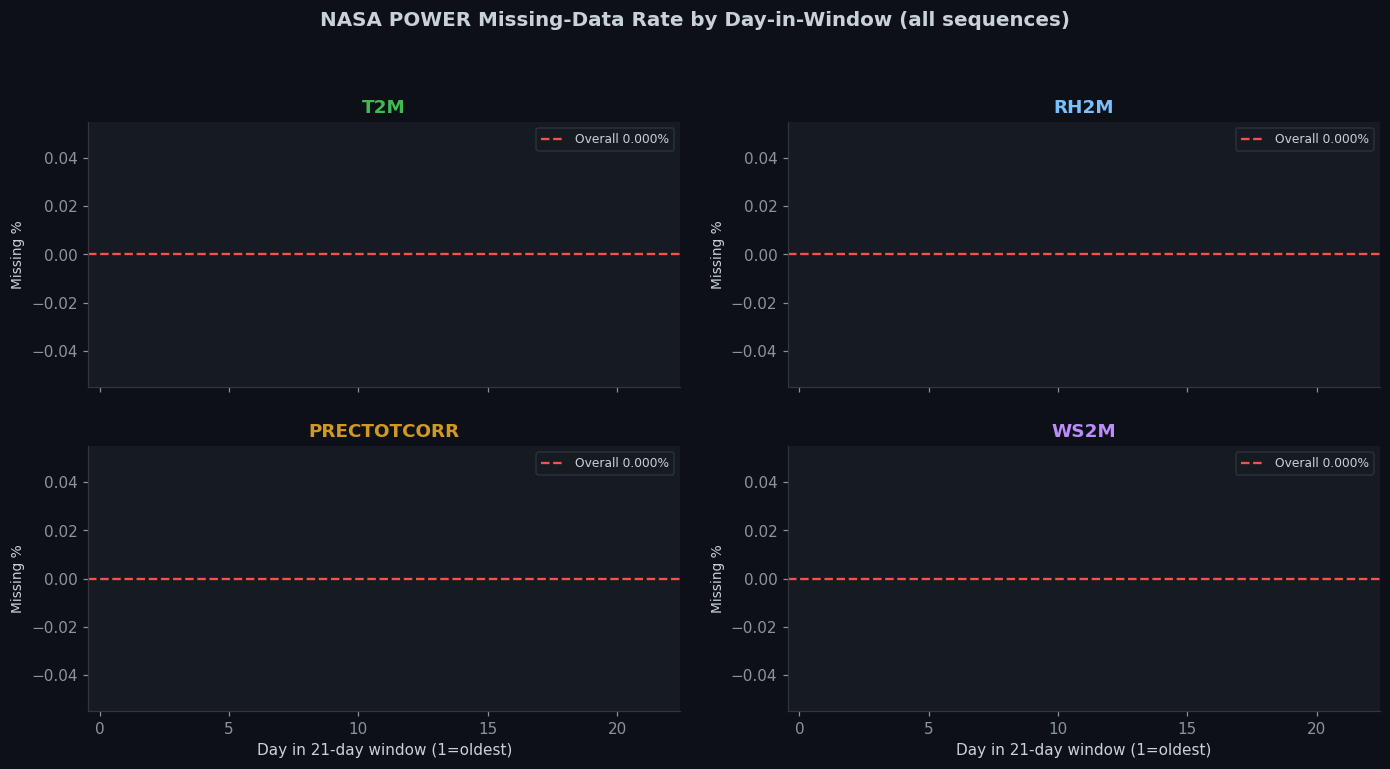

Fig 3 saved → outputs/nb02b_fig3_missingness_by_day.png


In [11]:
# ── C4-B: Figure — Missingness heatmap by time-step ─────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
fig.patch.set_facecolor('#0d1117')
fig.suptitle('NASA POWER Missing-Data Rate by Day-in-Window (all sequences)',
             color='#c9d1d9', fontweight='bold', fontsize=13, y=1.01)

colors_vars = [EMERALD, CYAN, AMBER, PURPLE]
for idx, (vname, col_idx) in enumerate(zip(var_names, [4,5,6,7])):
    ax = axes[idx//2][idx%2]
    ax.set_facecolor('#161b22')
    miss_by_day = X[:, :, col_idx].mean(axis=0) * 100   # (21,) mean miss rate per day
    ax.bar(range(1, 22), miss_by_day, color=colors_vars[idx], edgecolor='#0d1117',
           linewidth=0.3, alpha=0.9)
    ax.axhline(miss_by_day.mean(), color=RED, lw=1.5, ls='--',
               label=f'Overall {miss_by_day.mean():.3f}%')
    ax.set_title(vname, color=colors_vars[idx], fontweight='bold')
    ax.set_ylabel('Missing %', color='#c9d1d9', fontsize=9)
    ax.legend(fontsize=8)
    ax.tick_params(colors='#8b949e')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    if idx >= 2:
        ax.set_xlabel('Day in 21-day window (1=oldest)', color='#c9d1d9')

plt.tight_layout(pad=2)
fig.savefig(OUTPUTS/'nb02b_fig3_missingness_by_day.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Fig 3 saved → outputs/nb02b_fig3_missingness_by_day.png")

## C5 · Feature Engineering

25 features are computed from 4 raw weather variables and RAMSES survey events. 
They span **three tiers**:

| Tier | Features | Description |
|------|----------|-------------|
| Raw + Mask | T2M, RH2M, PRECTOTCORR, WS2M + 4 masks | Instantaneous weather + missingness |
| Survey signals | pest_surveyed, pest_event, pest_present | RAMSES activity flags |
| Rolling statistics | 7 features | 7-day & 21-day means, rain sums, temperature anomaly |
| Event counters | 5 features | Recency of survey & event, counts in window |

In [12]:
# ── C5-A: Feature-tier summary ──────────────────────────────────────────────
tiers = {
    'Raw Weather (4)' : list(range(0,4)),
    'Missingness Mask (4)' : list(range(4,8)),
    'Survey Signals (3)' : list(range(8,11)),
    'Rolling Stats (7)' : list(range(11,18)),
    'Anomaly (1)' : [19],
    'Event Counters (3)' : list(range(20,23)),
    'Recency Features (2)' : list(range(23,25)),
}
print(f"{'Feature Tier':<25}  {'Indices':<18}  {'Names'}")
print("─"*80)
for tier, idxs in tiers.items():
    names = ', '.join(FEATURES[i] for i in idxs)
    idx_str = f"{idxs[0]}–{idxs[-1]}" if len(idxs)>1 else str(idxs[0])
    print(f"  {tier:<23}  {idx_str:<18}  {names}")

Feature Tier               Indices             Names
────────────────────────────────────────────────────────────────────────────────
  Raw Weather (4)          0–3                 T2M, RH2M, PRECTOTCORR, WS2M
  Missingness Mask (4)     4–7                 w_mask_T2M, w_mask_RH2M, w_mask_PRECTOTCORR, w_mask_WS2M
  Survey Signals (3)       8–10                pest_surveyed, pest_event, pest_present
  Rolling Stats (7)        11–17               T2M_roll7_mean, T2M_roll21_mean, RH2M_roll7_mean, RH2M_roll21_mean, WS2M_roll7_mean, rain_sum7, rain_sum21
  Anomaly (1)              19                  t2m_anomaly
  Event Counters (3)       20–22               event_count_7d, event_count_21d, survey_count_21d
  Recency Features (2)     23–24               days_since_survey, days_since_event


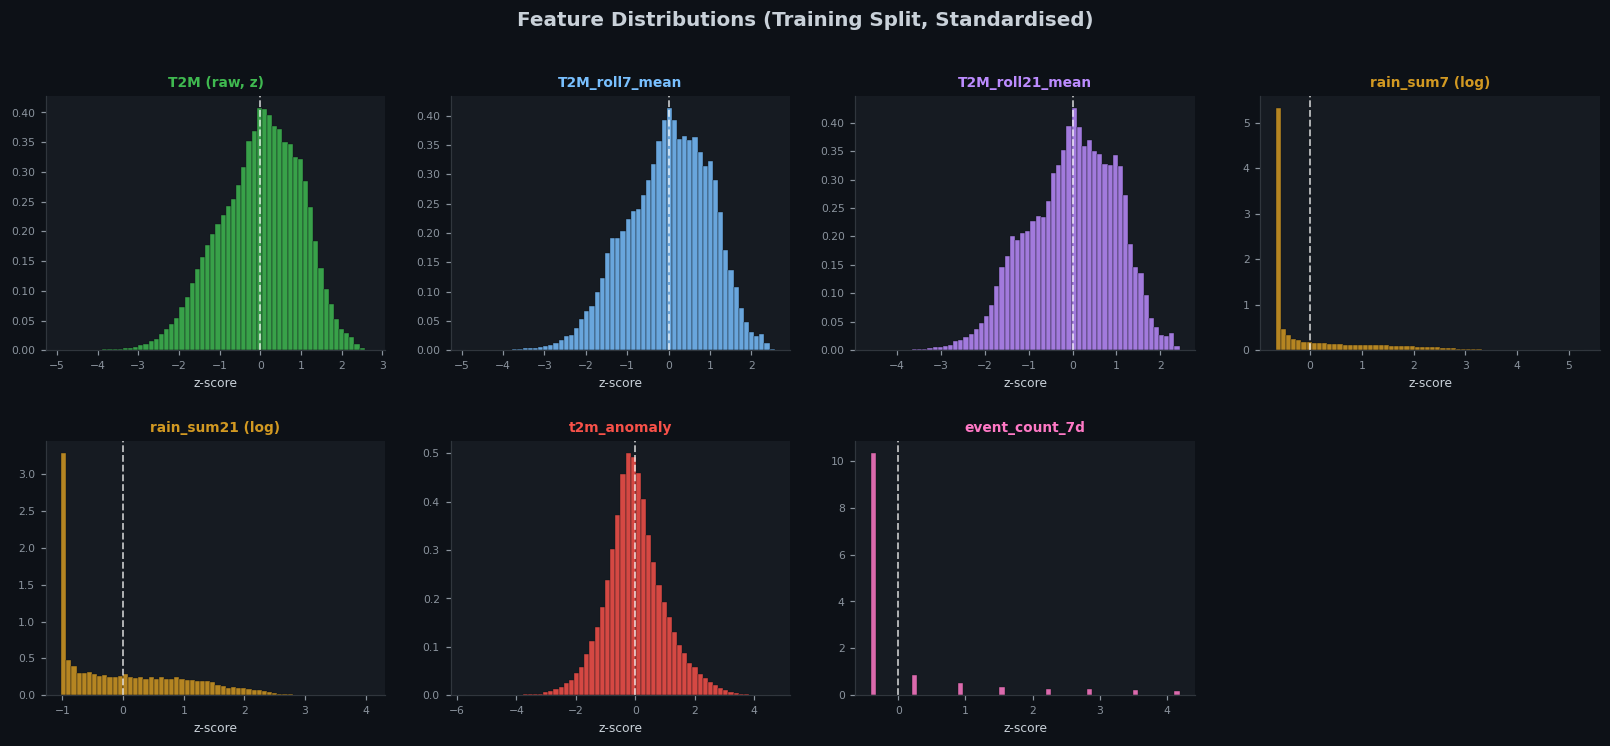

Fig 4 saved → outputs/nb02b_fig4_feature_distributions.png


In [13]:
# ── C5-B: Figure — Raw vs engineered feature distributions ──────────────────
# Compare key raw vs derived features on the TRAINING split
tr_mask = split == 0
X_tr    = X[tr_mask]  # (N_train, 21, 25)
# Flatten day dimension
X_flat  = X_tr.reshape(-1, 25)   # (N_train*21, 25)

SHOW = [0, 11, 12, 16, 17, 19, 20]  # T2M raw, T2M_roll7, T2M_roll21, rain_sum7, rain_sum21, t2m_anomaly, event_count_7d
SHOW_NAMES = ['T2M (raw, z)', 'T2M_roll7_mean', 'T2M_roll21_mean',
              'rain_sum7 (log)', 'rain_sum21 (log)', 't2m_anomaly', 'event_count_7d']
SHOW_COLORS = [EMERALD, CYAN, PURPLE, AMBER, AMBER, RED, '#ff79c6']

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.flatten()
fig.patch.set_facecolor('#0d1117')
fig.suptitle('Feature Distributions (Training Split, Standardised)', 
             color='#c9d1d9', fontweight='bold', fontsize=13)

for ax, fi, fn, fc in zip(axes, SHOW, SHOW_NAMES, SHOW_COLORS):
    ax.set_facecolor('#161b22')
    vals = X_flat[:, fi]
    vals_finite = vals[np.isfinite(vals)]
    ax.hist(vals_finite, bins=60, color=fc, edgecolor='#0d1117', linewidth=0.3, alpha=0.85, density=True)
    ax.axvline(vals_finite.mean(), color='white', lw=1.2, ls='--', alpha=0.7)
    ax.set_title(fn, color=fc, fontsize=9, fontweight='bold')
    ax.set_xlabel('z-score', color='#c9d1d9', fontsize=8)
    ax.tick_params(colors='#8b949e', labelsize=7)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

axes[-1].set_visible(False)
plt.tight_layout(pad=2)
fig.savefig(OUTPUTS/'nb02b_fig4_feature_distributions.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Fig 4 saved → outputs/nb02b_fig4_feature_distributions.png")

## C6 · Train-Only Z-Score Scaling (No Data Leakage)

A critical ML hygiene rule: **scaler statistics are computed only from the training 
split** and applied to validation/test. This prevents leakage of future statistics 
into the past.

The pipeline uses 18 continuous channels (excluding 7 binary mask/event channels):

`
z = (x − μ_train) / σ_train
`

Missing values (NaN) are filled with the **training-set mean** before scaling, 
preserving the mask channel as the signal for missingness.

In [14]:
# ── C6-A: Show scaler statistics ────────────────────────────────────────────
mean_arr = np.array(scaler['mean'])
std_arr  = np.array(scaler['std'])
fill_arr = np.array(scaler['fill'])

print(f"{'Feature':<22}  {'cont_idx':>8}  {'mean':>10}  {'std':>10}  {'fill':>10}")
print("─"*65)
for rank, (ci, feat_i) in enumerate(zip(CONT_IDX, CONT_IDX)):
    fname = FEATURES[ci] if ci < len(FEATURES) else f'feat_{ci}'
    print(f"  {fname:<20}  {ci:>8}  {mean_arr[rank]:>10.4f}  "
          f"{std_arr[rank]:>10.4f}  {fill_arr[rank]:>10.4f}")

print(f"\nTrain rows used for scaling: {scaler['n_train_rows']:,}")
print(f"Non-train rows (val+test)   : {scaler['n_nontrain_rows']:,}")
print(f"Train-only flag             : {scaler['train_only']}")

Feature                 cont_idx        mean         std        fill
─────────────────────────────────────────────────────────────────
  T2M                          0     26.4080      6.4041     26.4080
  RH2M                         1     43.7628     19.5293     43.7628
  PRECTOTCORR                  2      0.7512      4.5251      0.7512
  WS2M                         3      3.0892      1.2252      3.0892
  T2M_roll7_mean              11     26.3271      6.3162     26.3271
  T2M_roll21_mean             12     26.1878      6.3277     26.1878
  RH2M_roll7_mean             13     43.9882     18.2033     43.9882
  RH2M_roll21_mean            14     44.3838     17.3236     44.3838
  WS2M_roll7_mean             15      3.0850      0.9432      3.0850
  rain_sum7                   16      0.7778      1.1773      0.7778
  rain_sum21                  17      1.5787      1.5458      1.5787
  rain_days21                 18     20.9332      0.8550     20.9332
  t2m_anomaly                 19     

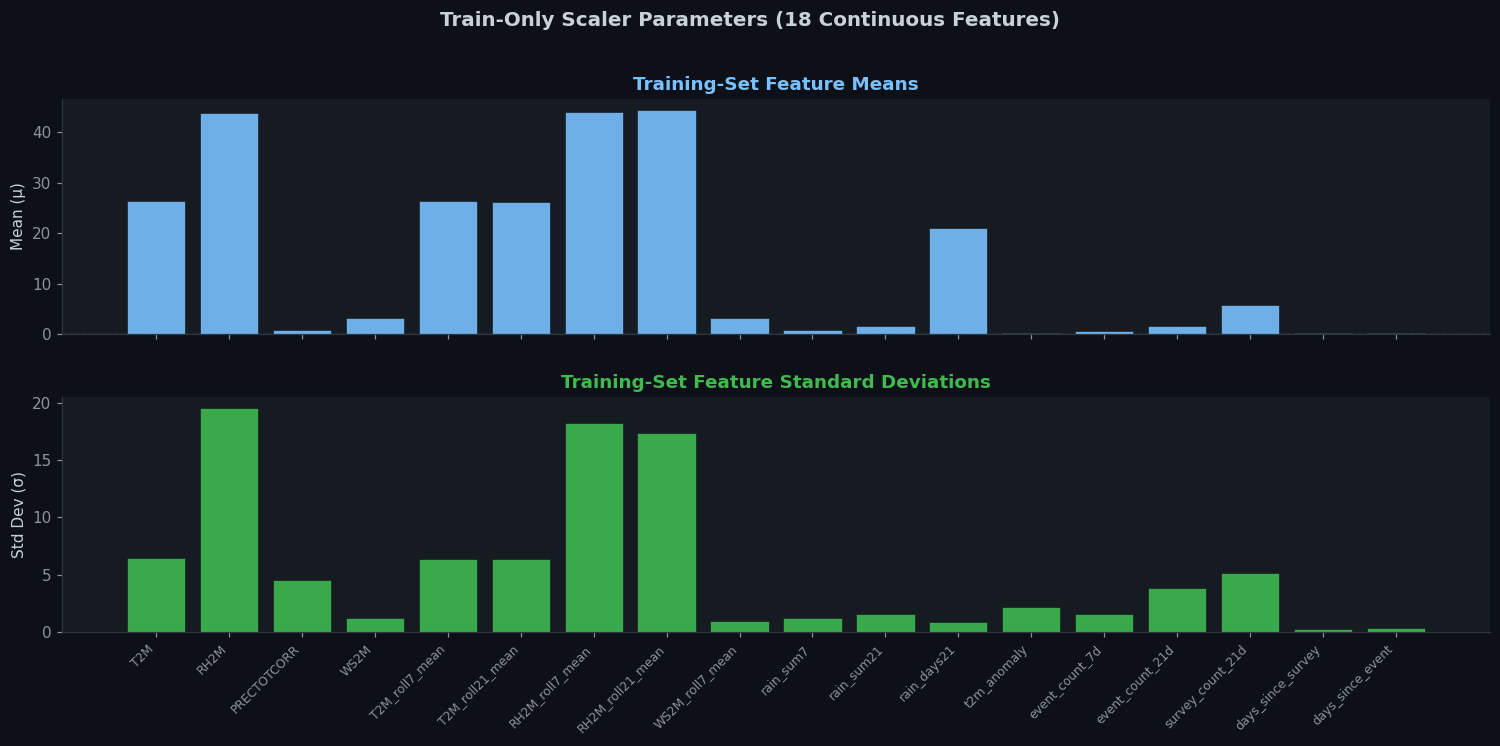

Fig 5 saved → outputs/nb02b_fig5_scaler_stats.png


In [15]:
# ── C6-B: Figure — μ and σ of each continuous feature ───────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
fig.patch.set_facecolor('#0d1117')
fig.suptitle('Train-Only Scaler Parameters (18 Continuous Features)',
             color='#c9d1d9', fontweight='bold', fontsize=13)

feat_labels = [FEATURES[i] for i in CONT_IDX]
x = np.arange(len(feat_labels))

ax1.set_facecolor('#161b22')
bars1 = ax1.bar(x, mean_arr, color=CYAN, edgecolor='#0d1117', linewidth=0.4, alpha=0.9)
ax1.axhline(0, color='#8b949e', lw=0.8, ls='--')
ax1.set_ylabel('Mean (μ)', color='#c9d1d9')
ax1.set_title('Training-Set Feature Means', color=CYAN, fontweight='bold')
ax1.tick_params(colors='#8b949e')
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)

ax2.set_facecolor('#161b22')
bars2 = ax2.bar(x, std_arr, color=EMERALD, edgecolor='#0d1117', linewidth=0.4, alpha=0.9)
ax2.set_ylabel('Std Dev (σ)', color='#c9d1d9')
ax2.set_title('Training-Set Feature Standard Deviations', color=EMERALD, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(feat_labels, rotation=45, ha='right', fontsize=8, color='#8b949e')
ax2.tick_params(colors='#8b949e')
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)

plt.tight_layout(pad=2)
fig.savefig(OUTPUTS/'nb02b_fig5_scaler_stats.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Fig 5 saved → outputs/nb02b_fig5_scaler_stats.png")

## C7 · Temporal Embargo Splits (28-day Gap)

Temporal data requires special care to avoid **look-ahead leakage**. The dataset 
uses fixed boundary dates with a **28-day embargo gap** between splits:

| Split | Label | Date Range | Embargo Gap |
|-------|-------|------------|-------------|
| Train | 0 | 2023-01-21 → 2025-06-05 | — |
| *Embargo* | — | 2025-06-06 → 2025-07-10 | 35 days |
| Validation | 1 | 2025-07-11 → 2026-01-05 | — |
| *Embargo* | — | 2026-01-06 → 2026-02-09 | 35 days |
| Test | 2 | 2026-02-10 → 2026-09-08 | — |

The embargo prevents sequences in train from having their **forecast horizon overlap** 
with the validation/test periods.

In [16]:
# ── C7-A: Split statistics ────────────────────────────────────────────────────
split_names = {0:'Train', 1:'Validation', 2:'Test'}
print(f"{'Split':<12} {'Count':>8} {'Positives':>10} {'Pos %':>8} {'Date Range'}")
print("─"*65)
for s in [0, 1, 2]:
    mask = split == s
    n    = mask.sum()
    pos  = y[mask].sum()
    dmin = min(dates[mask])
    dmax = max(dates[mask])
    print(f"  {split_names[s]:<10} {n:>8,} {int(pos):>10,} {100*pos/n:>8.2f}%  "
          f"{dmin} → {dmax}")

total = len(y)
print(f"\n  Total sequences : {total:,}")
print(f"  Overall pos rate: {100*y.mean():.2f}%")

Split           Count  Positives    Pos % Date Range
─────────────────────────────────────────────────────────────────
  Train        35,583      6,025    16.93%  2023-01-21 → 2025-06-05
  Validation    6,277      1,013    16.14%  2025-07-11 → 2026-01-05
  Test          6,684      1,320    19.75%  2026-02-10 → 2026-09-08

  Total sequences : 48,544
  Overall pos rate: 17.22%


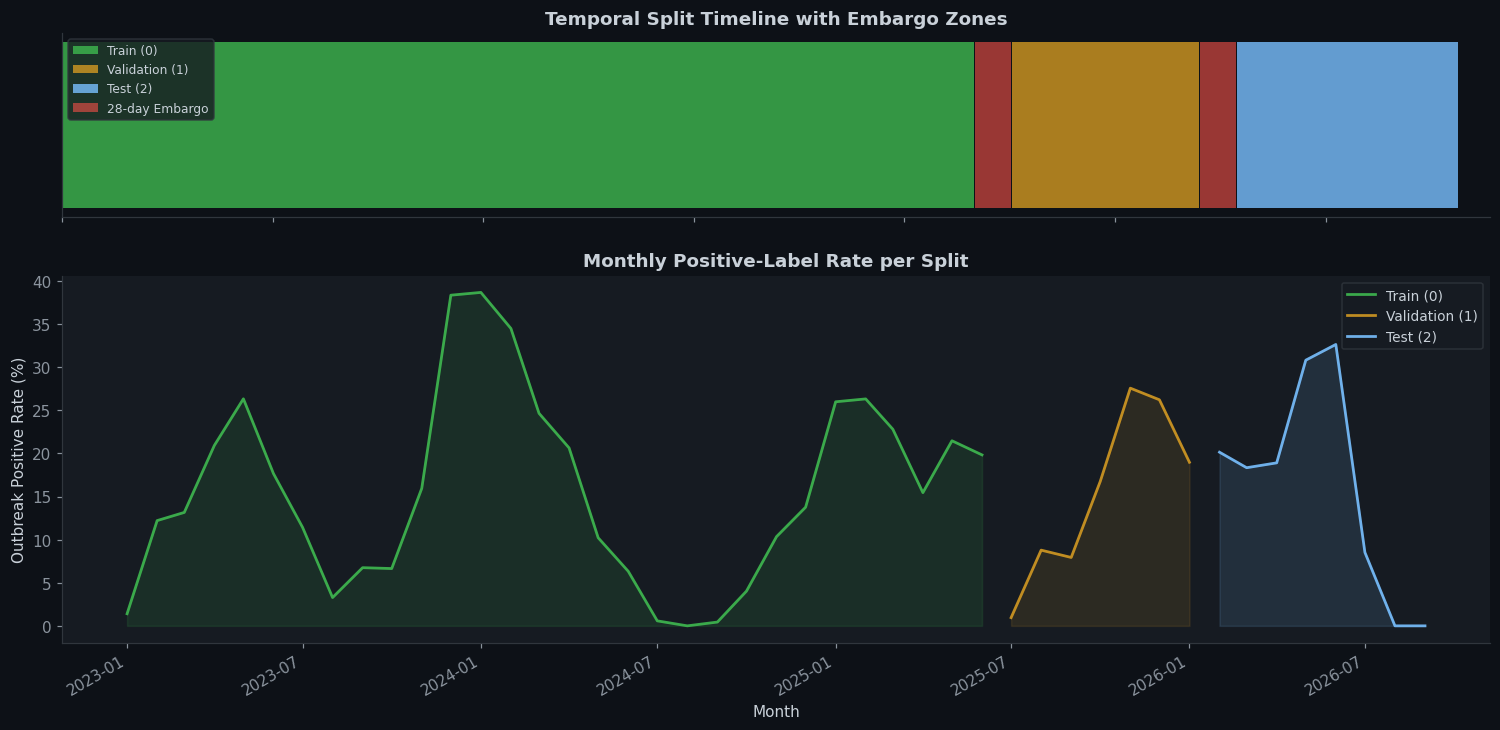

Fig 6 saved → outputs/nb02b_fig6_temporal_splits.png


In [17]:
# ── C7-B: Figure — Temporal split timeline with class balance ────────────────
dates_pd = pd.to_datetime(dates)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7),
                               gridspec_kw={'height_ratios':[1,2]})
fig.patch.set_facecolor('#0d1117')

# Top: timeline bands
ax1.set_facecolor('#0d1117')
split_colors = {0:EMERALD, 1:AMBER, 2:CYAN}
split_labels = {0:'Train (0)', 1:'Validation (1)', 2:'Test (2)'}
for s in [0,1,2]:
    mask = split == s
    d_arr = dates_pd[mask]
    ax1.barh(0, (d_arr.max()-d_arr.min()).days, left=(d_arr.min()-dates_pd.min()).days,
             height=0.5, color=split_colors[s], alpha=0.8, label=split_labels[s])
# Embargo zones
embargo_zones = [
    (pd.Timestamp('2025-06-06'), pd.Timestamp('2025-07-10')),
    (pd.Timestamp('2026-01-06'), pd.Timestamp('2026-02-09')),
]
for ez_start, ez_end in embargo_zones:
    ax1.barh(0, (ez_end-ez_start).days, left=(ez_start-dates_pd.min()).days,
             height=0.5, color=RED, alpha=0.6, label='28-day Embargo' if ez_start==embargo_zones[0][0] else '')
ax1.set_xlim(0, (dates_pd.max()-dates_pd.min()).days + 30)
ax1.set_yticks([])
ax1.set_xlabel('Days from dataset start (2023-01-21)', color='#c9d1d9')
ax1.set_title('Temporal Split Timeline with Embargo Zones', color='#c9d1d9', fontweight='bold')
ax1.legend(loc='upper left', fontsize=8)
ax1.tick_params(colors='#8b949e')
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)

# Bottom: monthly positive rate per split
ax2.set_facecolor('#161b22')
df_tmp = pd.DataFrame({'date': dates_pd, 'y': y, 'split': split})
df_tmp['month'] = df_tmp['date'].dt.to_period('M')
monthly = df_tmp.groupby(['month','split']).agg(pos=('y','sum'), n=('y','count')).reset_index()
monthly['pos_rate'] = monthly['pos'] / monthly['n'] * 100
for s in [0,1,2]:
    sub = monthly[monthly['split']==s].sort_values('month')
    ax2.plot(sub['month'].dt.to_timestamp(), sub['pos_rate'], 
             color=split_colors[s], lw=1.8, label=split_labels[s], alpha=0.9)
    ax2.fill_between(sub['month'].dt.to_timestamp(), sub['pos_rate'], alpha=0.12, color=split_colors[s])
ax2.set_xlabel('Month', color='#c9d1d9')
ax2.set_ylabel('Outbreak Positive Rate (%)', color='#c9d1d9')
ax2.set_title('Monthly Positive-Label Rate per Split', color='#c9d1d9', fontweight='bold')
ax2.legend(fontsize=9)
ax2.tick_params(colors='#8b949e', axis='both')
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
fig.autofmt_xdate()

plt.tight_layout(pad=2)
fig.savefig(OUTPUTS/'nb02b_fig6_temporal_splits.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Fig 6 saved → outputs/nb02b_fig6_temporal_splits.png")

## C8 · Artifact Validation & Provenance Checks

The pipeline enforces several **automated guardrails** to catch preprocessing errors 
before training:

In [18]:
# ── C8-A: Run all provenance checks ─────────────────────────────────────────
checks = []

# 1. No NaN in final X
no_nan = np.isfinite(X.astype(np.float64)).all()
checks.append(('No NaN/Inf in X', no_nan, f'X shape={X.shape}'))

# 2. Binary channels are strictly 0 or 1
bin_check = all(np.isin(X[:,:,i], [0.0, 1.0]).all() for i in BIN_IDX)
checks.append(('Binary channels ∈ {0,1}', bin_check, f'cols={BIN_IDX}'))

# 3. Train positives ≥ 30 (guardrail)
for s, name in [(0,'Train'),(1,'Val'),(2,'Test')]:
    pos = int(y[split==s].sum())
    checks.append((f'{name} positives ≥ 30', pos >= 30, f'pos={pos:,}'))

# 4. Splits are mutually exclusive and cover all rows
split_union = ((split==0) | (split==1) | (split==2))
checks.append(('All rows assigned a split', split_union.all(),
               f'unassigned={int((~split_union).sum())}'))

# 5. Dates are chronologically sorted
date_sorted = all(dates[i] <= dates[i+1] for i in range(len(dates)-1))
checks.append(('dates[] are non-decreasing', date_sorted, 'chronological order'))

# 6. Scaler used train-only stats
checks.append(('Scaler is train-only', scaler['train_only'],
               f"n_train_rows={scaler['n_train_rows']:,}"))

# 7. Feature count matches manifest
feat_check = X.shape[2] == manifest['n_features']
checks.append(('X.shape[2] == n_features', feat_check,
               f"{X.shape[2]} == {manifest['n_features']}"))

# Report
print(f"{'Check':<40}  {'Status':>8}  Detail")
print("─"*80)
all_pass = True
for name, ok, detail in checks:
    icon = '✅' if ok else '❌'
    print(f"  {name:<38}  {icon}        {detail}")
    if not ok: all_pass = False

print(f"\n{'─'*80}")
print(f"  Overall: {'ALL CHECKS PASSED ✅' if all_pass else 'SOME CHECKS FAILED ❌'}")

Check                                       Status  Detail
────────────────────────────────────────────────────────────────────────────────
  No NaN/Inf in X                         ✅        X shape=(48544, 21, 25)
  Binary channels ∈ {0,1}                 ✅        cols=[4, 5, 6, 7, 8, 9, 10]
  Train positives ≥ 30                    ✅        pos=6,025
  Val positives ≥ 30                      ✅        pos=1,013
  Test positives ≥ 30                     ✅        pos=1,320
  All rows assigned a split               ✅        unassigned=0
  dates[] are non-decreasing              ✅        chronological order
  Scaler is train-only                    ✅        n_train_rows=35,583
  X.shape[2] == n_features                ✅        25 == 25

────────────────────────────────────────────────────────────────────────────────
  Overall: ALL CHECKS PASSED ✅


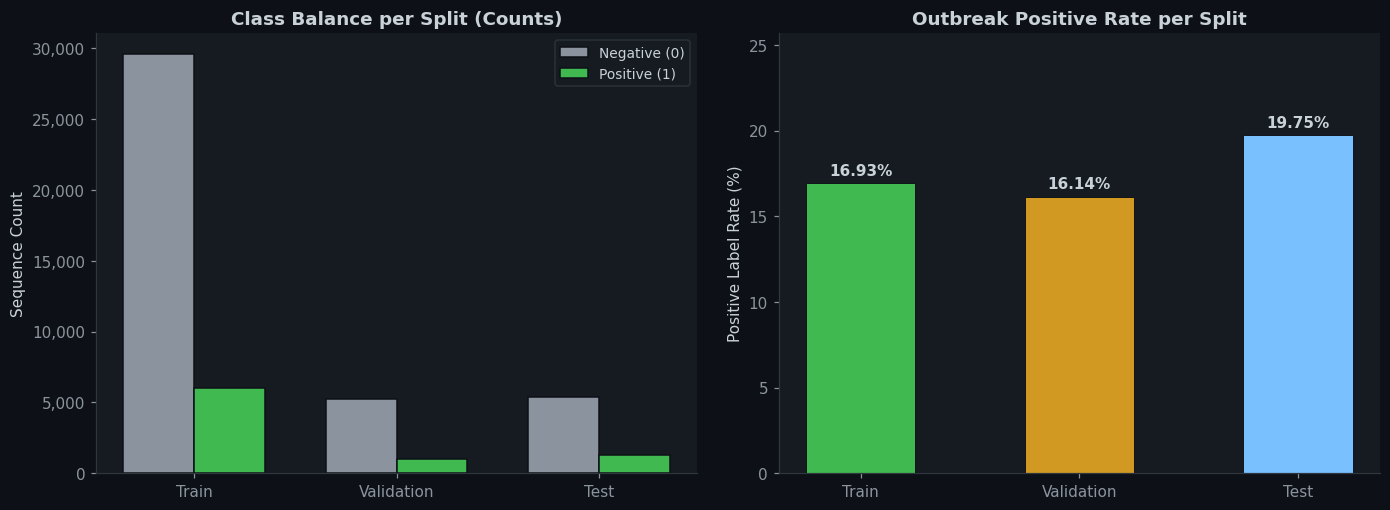

Fig 7 saved → outputs/nb02b_fig7_class_balance.png


In [19]:
# ── C8-B: Figure — Class balance per split (grouped bar) ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('#0d1117')

# Left: absolute counts
ax = axes[0]
ax.set_facecolor('#161b22')
split_ns  = [int((split==s).sum()) for s in [0,1,2]]
pos_ns    = [int(y[split==s].sum()) for s in [0,1,2]]
neg_ns    = [n-p for n,p in zip(split_ns, pos_ns)]
x = np.arange(3)
w = 0.35
ax.bar(x-w/2, neg_ns, w, label='Negative (0)', color='#8b949e', edgecolor='#0d1117')
ax.bar(x+w/2, pos_ns, w, label='Positive (1)', color=EMERALD, edgecolor='#0d1117')
ax.set_xticks(x); ax.set_xticklabels(['Train','Validation','Test'], color='#c9d1d9')
ax.set_ylabel('Sequence Count', color='#c9d1d9')
ax.set_title('Class Balance per Split (Counts)', color='#c9d1d9', fontweight='bold')
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v,_: f'{int(v):,}'))
ax.legend(fontsize=9); ax.tick_params(colors='#8b949e')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

# Right: positive rate %
ax2 = axes[1]
ax2.set_facecolor('#161b22')
pos_rates = [100*p/n for p,n in zip(pos_ns, split_ns)]
colors_bars = [EMERALD, AMBER, CYAN]
bars = ax2.bar(['Train','Validation','Test'], pos_rates,
               color=colors_bars, edgecolor='#0d1117', linewidth=0.6, width=0.5)
for bar, rate in zip(bars, pos_rates):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f'{rate:.2f}%', ha='center', va='bottom', color='#c9d1d9', fontsize=10, fontweight='bold')
ax2.set_ylabel('Positive Label Rate (%)', color='#c9d1d9')
ax2.set_title('Outbreak Positive Rate per Split', color='#c9d1d9', fontweight='bold')
ax2.tick_params(colors='#8b949e')
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.set_ylim(0, max(pos_rates)*1.3)

plt.tight_layout(pad=2)
fig.savefig(OUTPUTS/'nb02b_fig7_class_balance.png', dpi=130, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("Fig 7 saved → outputs/nb02b_fig7_class_balance.png")

## ✅ Pipeline Summary

| Stage | Input | Output | Key Action |
|-------|-------|--------|------------|
| C1 | Raw CSV files | Schema report | Inventory & dtype audit |
| C2 | RAMSES CSV | Cleaned records | DUBIOUS/UNCLEAR excluded |
| C3 | GPS coords | Grid cells | 0.5°×0.625° snap |
| C4 | POWER CSV | NaN-masked arrays | −999 sentinel → NaN + mask channel |
| C5 | Raw features | 25-feature tensor | Rolling stats, event counters, recency |
| C6 | Full tensor | Standardised X | Train-only μ/σ z-score scaling |
| C7 | Sorted sequences | Train/Val/Test | Fixed dates + 28-day embargo |
| C8 | sequences.npz | Validation report | Guardrail checks pass ✅ |

The cleaned, preprocessed dataset lives at data/processed/sequences.npz 
and is consumed by **Notebook 03** for model training.